# 01 · Dataset audit and leak-aware grouping

**Goal:** understand exactly what is in the PlantVillage folders *before* touching a model, and produce a `manifest` with a **group id** per image so related images of the same leaf never land in different splits.

Why this matters: PlantVillage photographs are taken under uniform lab conditions and many images are near-copies of each other (same leaf, rotated, flipped, re-cropped). A random split would put siblings in train *and* test, inflating accuracy. This notebook finds those families; notebook 02 refines them and builds the splits.

**What this notebook does not do:** it changes no image files. It only reads them and writes `artifacts/class_map.json` and `artifacts/manifest_v1.csv`.

### Step 1 - configuration and frozen class order
The ordered `artifacts/class_map.json` is the single source of truth for model output IDs. Keep its IDs contiguous and stable for this model version.

Prepare a curated dataset root with one subfolder per `folder` value in the class map. Each folder must contain reviewed images for that crop-condition class. The original PlantVillage directory should remain read-only; copy or link its applicable images into the curated layout. Pest photos may show the pest or characteristic crop damage.


In [2]:
pip install pandas

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 299.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 299.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 299.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 299.6 kB/s eta 0:00:31
   --- ------------------------------------ 0.8/9.7 MB 302.2 kB/s e

In [4]:
pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 329.3 kB/s eta 0:00:27
   -- ------------------------------------- 0.5/9.3 MB 329.3 kB/s eta 0:00:27
   -- ------------------------------------- 0.5/9.3 MB 329.3 kB/s eta 0:00:27
   -- ------------------------------------- 0.5/9.3 MB 329.3 kB/s eta 0:00:27
   --- ------------------------------------ 0.8/9.3 MB 325.8 kB/s e

  You can safely remove it manually.
  You can safely remove it manually.


In [ ]:
import json, hashlib, collections
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
ARTIFACTS = PROJECT_ROOT / "artifacts"; ARTIFACTS.mkdir(exist_ok=True)
DATA_ROOT = PROJECT_ROOT / "data" / "curated"  # one folder per class_map.json folder value
SEED = 42

class_map_path = ARTIFACTS / "class_map.json"
CLASSES = json.loads(class_map_path.read_text(encoding="utf-8"))
assert len(CLASSES) == 34, f"Expected the v2 34-class taxonomy, found {len(CLASSES)}"
assert [c["id"] for c in CLASSES] == list(range(len(CLASSES))), "Class IDs must be unique, ordered, and contiguous"
assert len({(c["crop"], c["condition"]) for c in CLASSES}) == len(CLASSES), "Duplicate crop-condition class"
pd.DataFrame(CLASSES)[["id", "label", "folder", "kind"]]


### Step 2 — inventory: what folders exist?
Folder names differ slightly between copies of the dataset, so we *verify* rather than assume. Folders we don't support (other tomato diseases, other crops) are **not** training data, but we record them: they become the **unsupported-condition** test set for the rejection mechanism later. Keep them untouched.

In [11]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
def list_images(folder: Path):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)

found = {d.name: len(list_images(d)) for d in sorted(DATA_ROOT.iterdir()) if d.is_dir()}
supported_folders = {c["folder"] for c in CLASSES}

missing = supported_folders - set(found)
assert not missing, f"Folders not found under DATA_ROOT (fix CLASSES[...]['folder']): {missing}"

print("SUPPORTED")
for c in CLASSES:
    print(f"  {c['id']}  {c['label']:<30} {found[c['folder']]:>6}")
print("\nUNSUPPORTED (kept aside for out-of-scope testing later)")
unsupported = {k: v for k, v in found.items() if k not in supported_folders}
for k, v in unsupported.items():
    print(f"  {k:<55} {v:>6}")
(ARTIFACTS / "unsupported_folders.json").write_text(json.dumps(unsupported, indent=2))

SUPPORTED
  0  maize__common_rust               1192
  1  maize__northern_leaf_blight       985
  2  maize__gray_leaf_spot             513
  3  maize__healthy                   1162
  4  tomato__bacterial_spot           2127
  5  tomato__early_blight             1000
  6  tomato__late_blight              1909
  7  tomato__leaf_mold                 952
  8  tomato__healthy                  1591

UNSUPPORTED (kept aside for out-of-scope testing later)


2

> **Sanity check:** the original PlantVillage colour set has roughly 1,000–2,100 images for the tomato classes and about 500–1,200 for the maize classes (from my recollection; treat these as a rough check, not a spec). If your counts are several times larger, you probably have an augmented copy, which would make leakage far worse. **Maize gray leaf spot is the smallest class**; expect to handle imbalance in training.

### Step 3 — build the manifest: integrity, size, exact-duplicate hash, quality, perceptual hashes
For every supported image we record: file integrity, dimensions, colour mode, an exact content hash (SHA-1, to find byte-identical files), blur score (variance of a Laplacian: low = blurry), mean brightness, and **eight perceptual hashes** (the image's 4 rotations × optional mirror). Comparing against all 8 variants makes the near-duplicate search insensitive to rotation and flips, which is exactly how PlantVillage siblings differ.

This takes a few minutes on CPU and runs in threads.

In [12]:
D4 = [(k, f) for k in range(4) for f in (False, True)]   # 8 dihedral variants

def dhash_variants(img: Image.Image):
    """8 x 64-bit difference hashes, one per rotation/mirror variant."""
    base = np.asarray(img.convert("L").resize((72, 72), Image.LANCZOS))
    out = []
    for k, flip in D4:
        v = np.rot90(base, k)
        if flip:
            v = np.fliplr(v)
        g = np.asarray(Image.fromarray(np.ascontiguousarray(v)).resize((9, 8), Image.BOX), dtype=np.int16)
        bits = (g[:, 1:] > g[:, :-1]).flatten()
        out.append(int("".join("1" if b else "0" for b in bits), 2))
    return out

def laplacian_var(gray: np.ndarray) -> float:
    g = gray.astype(np.float32)
    lap = (-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:])
    return float(lap.var())

def inspect(args):
    path, class_id = args
    rec = dict(path=str(path), file=path.name, class_id=class_id, ok=True, err="")
    try:
        data = path.read_bytes()
        rec["sha1"] = hashlib.sha1(data).hexdigest()
        rec["bytes"] = len(data)
        with Image.open(path) as im:
            im.load()
            im = ImageOps.exif_transpose(im)
            rec["w"], rec["h"], rec["mode"] = im.width, im.height, im.mode
            rgb = im.convert("RGB")
            small = rgb.resize((256, 256), Image.BILINEAR)
            gray = np.asarray(small.convert("L"))
            rec["blur"] = laplacian_var(gray)
            rec["brightness"] = float(gray.mean())
            rec["dh"] = dhash_variants(rgb)
    except Exception as e:                       # corrupt / unreadable file
        rec["ok"], rec["err"] = False, repr(e)
    return rec

jobs = [(p, c["id"]) for c in CLASSES for p in list_images(DATA_ROOT / c["folder"])]
print(len(jobs), "images to inspect")
with ThreadPoolExecutor(max_workers=8) as ex:
    records = list(ex.map(inspect, jobs))

df = pd.DataFrame(records)
df["label"] = df["class_id"].map({c["id"]: c["label"] for c in CLASSES})
print("unreadable files:", int((~df.ok).sum()))
df[~df.ok][["file", "label", "err"]].head(20)

11431 images to inspect
unreadable files: 0


,file,label,err


### Step 4 — basic quality review
Look at size/mode consistency and the blur/brightness distributions per class. We **flag** outliers for visual review; we don't auto-delete anything yet. Deleting is a decision to make after you've looked at examples.

image sizes (top 5):
 w    h  
256  256    11431
dtype: int64 

colour modes:
 mode
RGB    11431
Name: count, dtype: int64 

label           maize__common_rust  maize__gray_leaf_spot  maize__healthy  \
blur       min               474.4                  111.0             4.4   
           25%              1931.3                 1316.9           114.8   
           50%              2633.2                 2227.6           439.8   
           75%              3617.3                 4035.6          1561.4   
           max              8195.5                11193.3         14007.8   
brightness min                31.4                   61.0            51.4   
           25%                80.8                  111.7           132.1   
           50%                91.8                  118.6           151.2   
           75%               102.7                  123.9           166.6   
           max               156.1                  196.4           209.7   

label           maize__nort

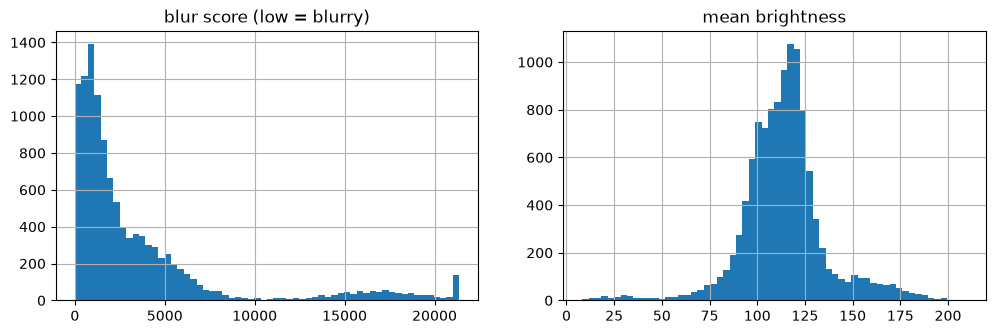

In [13]:
good = df[df.ok].copy()
print("image sizes (top 5):\n", good.groupby(["w", "h"]).size().sort_values(ascending=False).head(5), "\n")
print("colour modes:\n", good["mode"].value_counts(), "\n")
print(good.groupby("label")[["blur", "brightness"]].describe().round(1).T.loc[
    (slice(None), ["min", "25%", "50%", "75%", "max"]), :])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
good["blur"].clip(upper=good["blur"].quantile(0.99)).hist(bins=60, ax=ax[0]); ax[0].set_title("blur score (low = blurry)")
good["brightness"].hist(bins=60, ax=ax[1]); ax[1].set_title("mean brightness")
plt.show()

In [ ]:
def show(paths, titles=None, cols=6, size=2.2):
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for a in np.atleast_1d(axes).ravel(): a.axis("off")
    for i, p in enumerate(paths):
        a = np.atleast_1d(axes).ravel()[i]
        a.imshow(Image.open(p).convert("RGB"))
        if titles is not None: a.set_title(str(titles[i])[:28], fontsize=7)
    plt.tight_layout(); plt.show()

# 12 random images per class would be ideal; start with 1 row of 6 for each class
rng = np.random.default_rng(SEED)
for c in CLASSES:
    sub = good[good.class_id == c["id"]]
    pick = sub.sample(min(6, len(sub)), random_state=SEED)
    print(c["label"])
    show(pick.path.tolist(), cols=6)

**Do this by eye now.** Questions to answer for yourself: do the "healthy" leaves look genuinely healthy? Are labels plausible? Is the background identical in every class (it usually is, which creates a shortcut risk: the model can learn the *background/lighting*, not the disease; this is a known PlantVillage weakness and exactly why field-photo testing is mandatory)? Look at the lowest-blur images next.

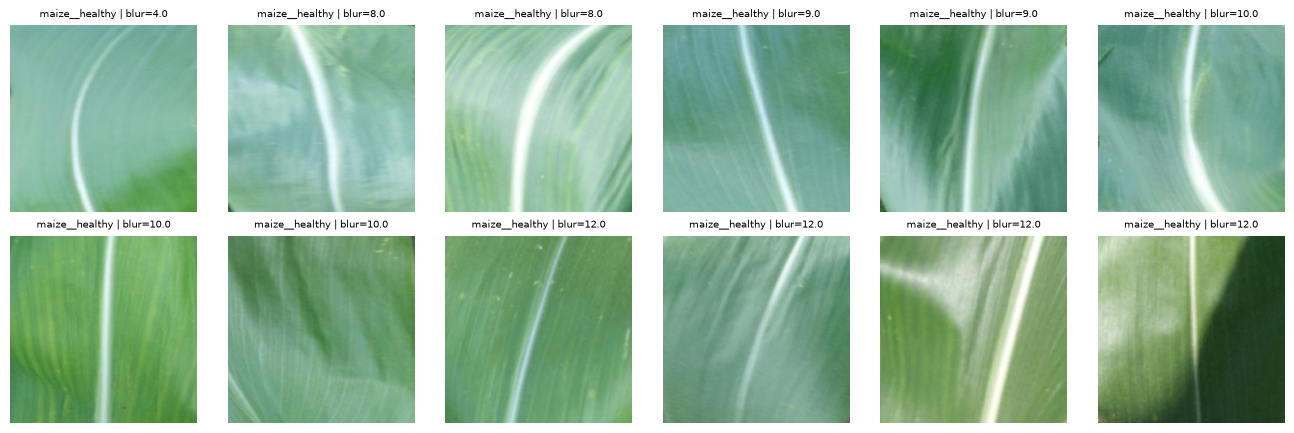

In [15]:
low = good.nsmallest(12, "blur")
show(low.path.tolist(), titles=(low.label + " | blur=" + low.blur.round(0).astype(str)).tolist(), cols=6)

### Step 5 — exact duplicates
Byte-identical files (same SHA-1). Within one class they just need to share a group. **The same hash appearing under two different labels is a labelling error** and needs to be removed.

In [16]:
dup = good.groupby("sha1").agg(n=("path", "size"), n_labels=("label", "nunique"))
print("files in exact-duplicate sets:", int(dup[dup.n > 1].n.sum()), "in", int((dup.n > 1).sum()), "sets")
conflict = dup[dup.n_labels > 1]
print("duplicate sets with CONFLICTING labels:", len(conflict))
good["conflict_label"] = good.sha1.isin(conflict.index)
good[good.conflict_label][["file", "label", "sha1"]].sort_values("sha1").head(20)

files in exact-duplicate sets: 28 in 14 sets
duplicate sets with CONFLICTING labels: 0


,file,label,sha1


### Step 6 — near-duplicate families (same leaf, rotated / flipped / re-cropped)
Within each class, two images are linked if the **minimum Hamming distance over the 8 orientation variants** of their 64-bit hashes is ≤ `HAMMING_T`. Links are merged transitively (union-find) into **groups**. A group is treated as one unit: all members go to the same split.

`HAMMING_T = 6` is a deliberately modest starting point. Too low misses siblings (leakage stays); too high merges different leaves (groups become huge and splits unbalanced). We examine the distance histogram and look at real groups before accepting it.

Limitation worth knowing: a perceptual hash catches copies and light edits, **not** a different photo of the same leaf from another angle. Notebook 02 adds an embedding-similarity pass for that.

In [17]:
HAMMING_T = 6

try:
    popcount = np.bitwise_count                      # NumPy >= 2.0
except AttributeError:
    _t = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    popcount = lambda a: _t[a.view(np.uint8).reshape(*a.shape, 8)].sum(-1)

class DSU:
    def __init__(s, n): s.p = list(range(n))
    def find(s, a):
        while s.p[a] != a:
            s.p[a] = s.p[s.p[a]]; a = s.p[a]
        return a
    def union(s, a, b):
        ra, rb = s.find(a), s.find(b)
        if ra != rb: s.p[rb] = ra

good = good.reset_index(drop=True)
H_all = np.array(good["dh"].tolist(), dtype=np.uint64)      # (N, 8)
dsu = DSU(len(good))
dist_hist = collections.Counter()

for cid in good.class_id.unique():
    idx = np.where(good.class_id.values == cid)[0]
    H = H_all[idx]                                          # (n, 8)
    base = H[:, 0]
    for s in range(0, len(idx), 256):
        x = base[s:s + 256, None, None] ^ H[None, :, :]     # (c, n, 8)
        d = popcount(x).min(axis=2).astype(np.int16)        # (c, n)
        for r in range(d.shape[0]):
            i = s + r
            d[r, :i + 1] = 99                               # only j > i
        for r, j in zip(*np.where(d <= HAMMING_T)):
            dsu.union(idx[s + r], idx[j]); dist_hist[int(d[r, j])] += 1

# exact duplicates always share a group
for _, g in good.groupby("sha1"):
    ids = g.index.tolist()
    for j in ids[1:]: dsu.union(ids[0], j)

good["group_v1"] = [dsu.find(i) for i in range(len(good))]
sizes = good.groupby("group_v1").size()
print("pairs linked by Hamming distance:", dict(sorted(dist_hist.items())))
print(f"{len(good)} images -> {len(sizes)} groups")
print("group size distribution:\n", sizes.describe().round(1))
print("largest groups:", sizes.sort_values(ascending=False).head(8).tolist())

pairs linked by Hamming distance: {0: 15, 1: 2, 2: 13, 3: 35, 4: 143, 5: 407, 6: 1072}
11431 images -> 10592 groups
group size distribution:
 count    10592.0
mean         1.1
std          3.7
min          1.0
25%          1.0
50%          1.0
75%          1.0
max        346.0
dtype: float64
largest groups: [346, 125, 84, 19, 16, 16, 8, 7]


### Step 7 — look at the groups you just made
Review the **largest** groups (could be over-merged) and a few random multi-image groups (should be genuinely the same leaf). If large groups contain visibly different leaves, lower `HAMMING_T` and rerun Step 6. If obvious siblings are in separate groups, that's what the embedding pass in notebook 02 is for.

178 groups with more than one image; 1017 images involved (8.9% of the dataset)
largest-group sample | size=346 | maize__common_rust


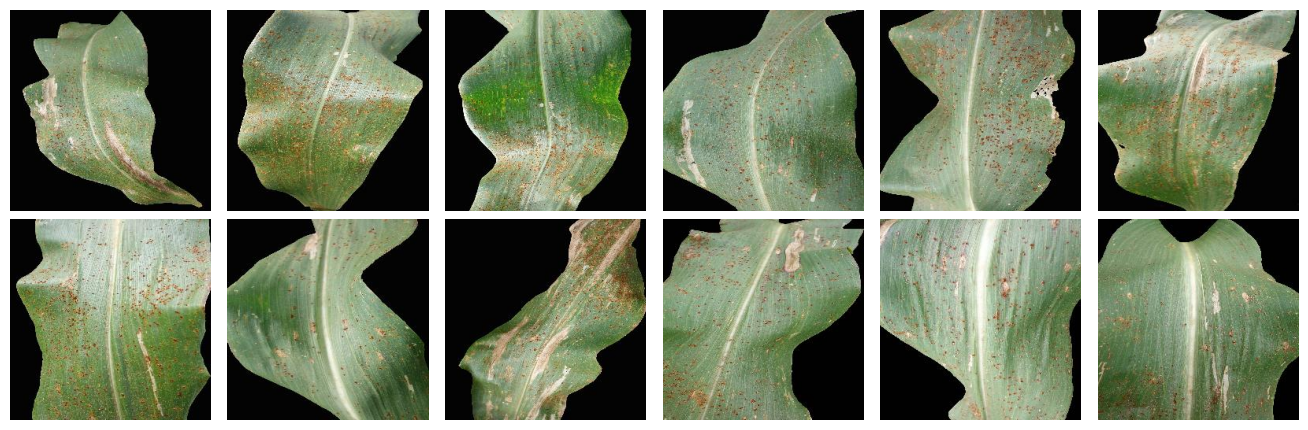

largest-group sample | size=125 | tomato__bacterial_spot


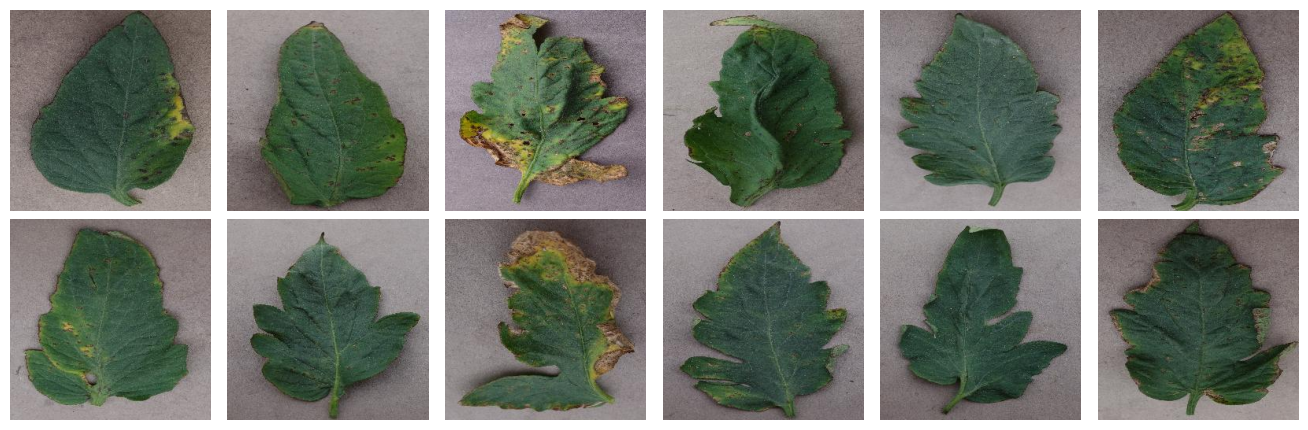

largest-group sample | size=84 | tomato__late_blight


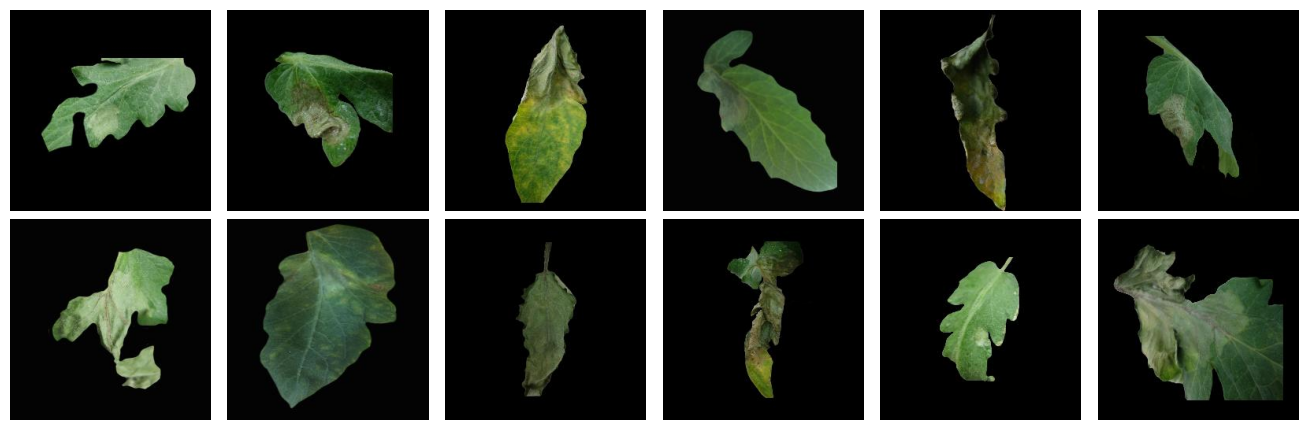

random group | size=2 | maize__common_rust


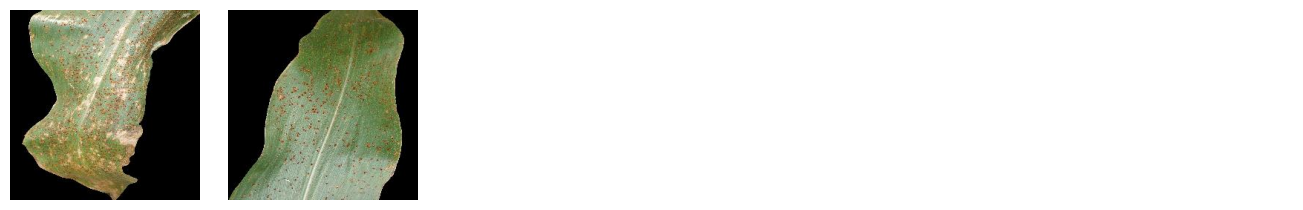

random group | size=2 | maize__healthy


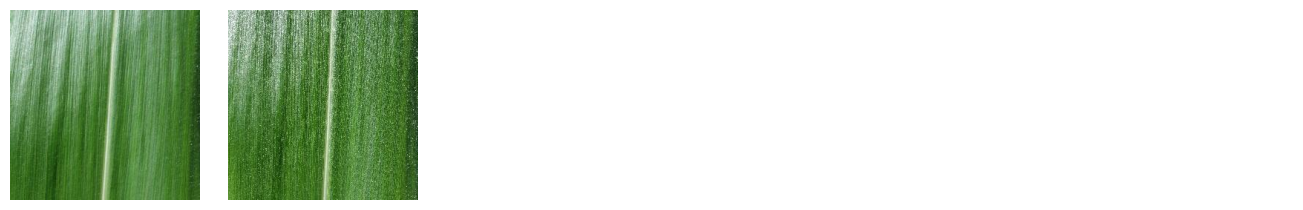

random group | size=16 | tomato__late_blight


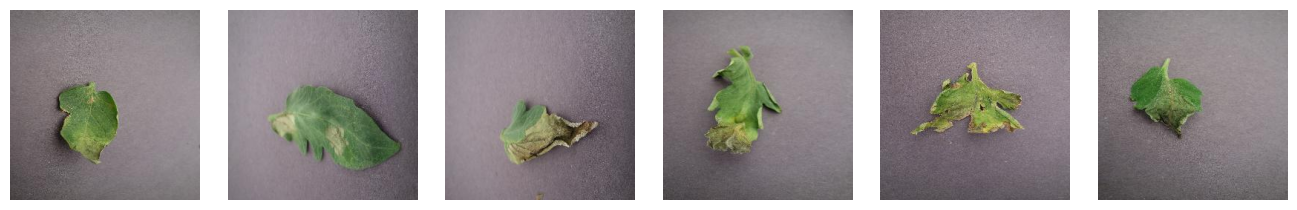

In [18]:
multi = sizes[sizes > 1]
print(f"{len(multi)} groups with more than one image; {int(multi.sum())} images involved "
      f"({multi.sum() / len(good):.1%} of the dataset)")

for gid in multi.sort_values(ascending=False).head(3).index:
    g = good[good.group_v1 == gid].head(12)
    print(f"largest-group sample | size={int(sizes[gid])} | {g.label.iloc[0]}")
    show(g.path.tolist(), cols=6)

for gid in multi.sample(3, random_state=SEED).index:
    g = good[good.group_v1 == gid].head(6)
    print(f"random group | size={int(sizes[gid])} | {g.label.iloc[0]}")
    show(g.path.tolist(), cols=6)

### Step 8 — save the manifest
Nothing is dropped here, only flagged: unreadable files, conflicting-label duplicates, and a `blur_flag` for the blurriest 1 % per class (for you to review, not an automatic rule). `group_v1` is provisional; notebook 02 produces the final `group_id` and the splits.

In [19]:
thr = good.groupby("class_id")["blur"].transform(lambda s: s.quantile(0.01))
good["blur_flag"] = good["blur"] <= thr

out = good.drop(columns=["dh", "ok", "err"]).copy()
out["sha1"] = out["sha1"].astype(str)
out.to_csv(ARTIFACTS / "manifest_v1.csv", index=False)

print("saved", ARTIFACTS / "manifest_v1.csv", "| rows:", len(out))
print("unreadable (excluded from manifest):", int((~df.ok).sum()))
print("conflicting-label duplicates flagged:", int(out.conflict_label.sum()))
print("blur-flagged for review:", int(out.blur_flag.sum()))
out.groupby("label").agg(images=("path", "size"), groups=("group_v1", "nunique")).assign(
    imgs_per_group=lambda d: (d.images / d.groups).round(2))

saved C:\Users\baabyface\Documents\my work\agrilens\artifacts\manifest_v1.csv | rows: 11431
unreadable (excluded from manifest): 0
conflicting-label duplicates flagged: 0
blur-flagged for review: 118


,images,groups,imgs_per_group
label,,,
maize__common_rust,1192,821,1.45
maize__gray_leaf_spot,513,505,1.02
maize__healthy,1162,1128,1.03
maize__northern_leaf_blight,985,967,1.02
tomato__bacterial_spot,2127,1919,1.11
tomato__early_blight,1000,996,1.00
tomato__healthy,1591,1557,1.02
tomato__late_blight,1909,1761,1.08
tomato__leaf_mold,952,938,1.01


In [20]:
MAX_T = 10
pi_l, pj_l, pd_l = [], [], []
for cid in good.class_id.unique():
    idx = np.where(good.class_id.values == cid)[0]
    H = H_all[idx]
    base = H[:, 0]
    for s in range(0, len(idx), 256):
        x = base[s:s + 256, None, None] ^ H[None, :, :]
        d = popcount(x).min(axis=2).astype(np.int16)
        for r in range(d.shape[0]):
            d[r, :s + r + 1] = 99                      # keep only j > i
        rr, jj = np.where(d <= MAX_T)
        pi_l.append(idx[s + rr]); pj_l.append(idx[jj]); pd_l.append(d[rr, jj])
PI, PJ, PDIST = (np.concatenate(a) for a in (pi_l, pj_l, pd_l))

exact = [g.index.tolist() for _, g in good.groupby("sha1") if len(g) > 1]

rows = []
for T in range(0, MAX_T + 1):
    dsu_t = DSU(len(good))
    for ids in exact:
        for j in ids[1:]:
            dsu_t.union(ids[0], j)
    m = PDIST <= T
    for a, b in zip(PI[m], PJ[m]):
        dsu_t.union(int(a), int(b))
    gid = np.array([dsu_t.find(i) for i in range(len(good))])
    sz = np.bincount(np.unique(gid, return_inverse=True)[1])
    rows.append(dict(T=T, pairs_linked=int(m.sum()), groups=len(sz),
                     images_in_multi_groups=int(sz[sz > 1].sum()),
                     largest=int(sz.max()), top3=sorted(sz.tolist(), reverse=True)[:3]))
pd.DataFrame(rows)

,T,pairs_linked,groups,images_in_multi_groups,largest,top3
0,0,15,11416,30,2,"[2, 2, 2]"
1,1,17,11414,34,2,"[2, 2, 2]"
2,2,30,11401,55,4,"[4, 3, 3]"
3,3,65,11372,94,15,"[15, 5, 4]"
4,4,208,11264,240,65,"[65, 24, 6]"
5,5,615,11017,545,174,"[174, 54, 13]"
6,6,1687,10592,1017,346,"[346, 125, 84]"
7,7,4374,9856,1802,551,"[551, 445, 198]"
8,8,10324,8856,2867,877,"[877, 750, 327]"
9,9,22740,7681,4046,1297,"[1297, 921, 500]"


In [21]:
# A real family: most member pairs are within T of EACH OTHER (share near 1.0).
# A chain (A~B, B~C, C~D ... but A and D unrelated): share is low and the median distance is high.
# For scale, two unrelated images typically sit around 20+ bits apart.

for gid in sizes.sort_values(ascending=False).head(5).index:
    ids = good.index[good.group_v1 == gid].to_numpy()
    D = np.array([popcount(H_all[a, 0] ^ H_all[ids]).min(axis=1) for a in ids])
    off = D[~np.eye(len(ids), dtype=bool)]
    print(f"{good.label[ids[0]]:<32} size={len(ids):>4}  "
          f"pairs within T: {(off <= HAMMING_T).mean():.3f}  "
          f"median pair distance: {np.median(off):.0f}  max: {off.max()}")


maize__common_rust               size= 346  pairs within T: 0.018  median pair distance: 13  max: 30
tomato__bacterial_spot           size= 125  pairs within T: 0.017  median pair distance: 13  max: 26
tomato__late_blight              size=  84  pairs within T: 0.051  median pair distance: 12  max: 37
maize__healthy                   size=  19  pairs within T: 0.091  median pair distance: 22  max: 33
tomato__late_blight              size=  16  pairs within T: 0.067  median pair distance: 16  max: 28


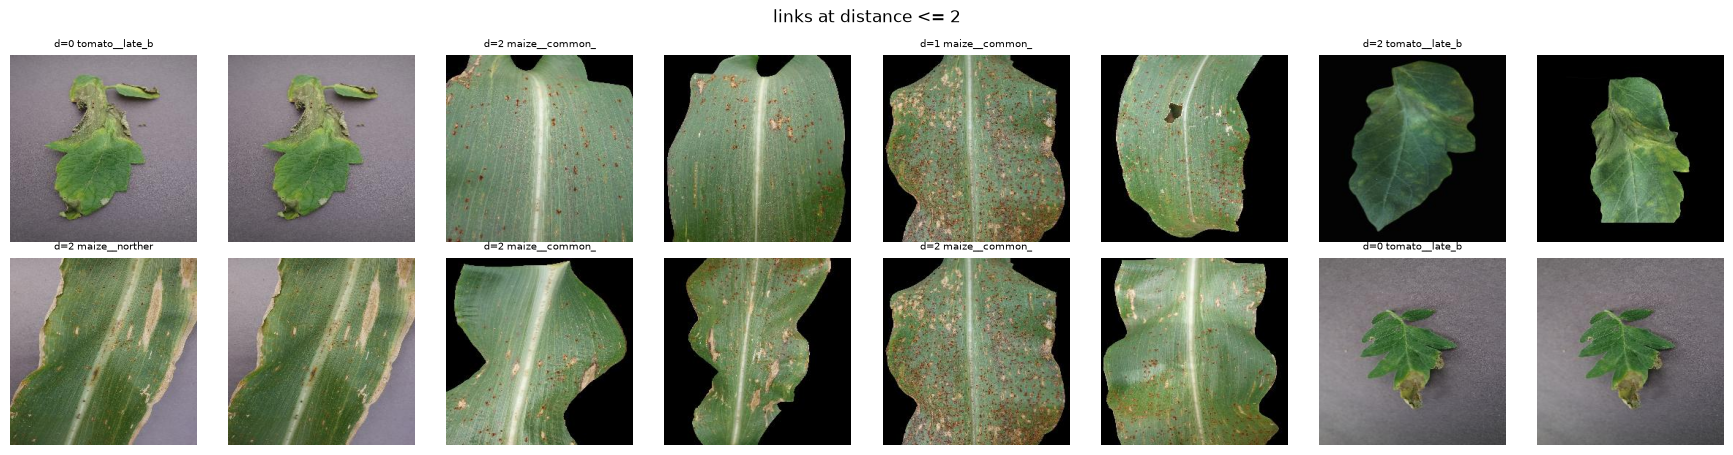

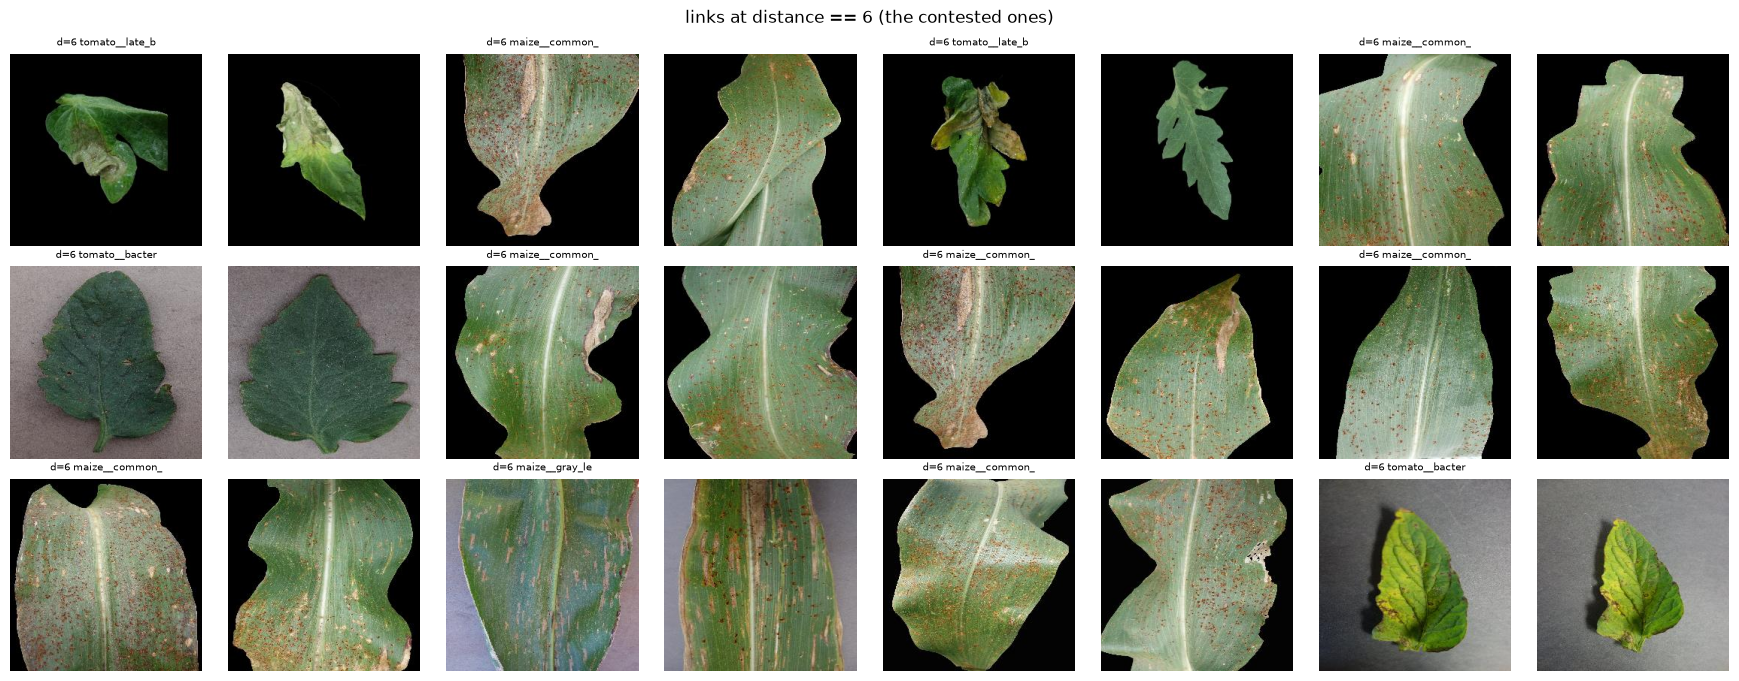

In [22]:
# Left column pairs are links at distance <= 2 (should be obvious copies);
# the others are links at exactly HAMMING_T, the ones the threshold is deciding about.
def show_pairs(sel, title, cols=4):
    n = len(sel)
    fig, axes = plt.subplots((n + cols - 1) // cols, cols * 2, figsize=(cols * 4.4, ((n + cols - 1) // cols) * 2.3))
    for a in np.atleast_1d(axes).ravel(): a.axis("off")
    ax = np.atleast_1d(axes).ravel()
    for k, e in enumerate(sel):
        ax[2 * k].imshow(Image.open(good.path[PI[e]]).convert("RGB"))
        ax[2 * k + 1].imshow(Image.open(good.path[PJ[e]]).convert("RGB"))
        ax[2 * k].set_title(f"d={PDIST[e]} {good.label[PI[e]][:14]}", fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
low = np.where(PDIST <= 2)[0]
edge = np.where(PDIST == HAMMING_T)[0]
show_pairs(rng.choice(low, 8, replace=False), "links at distance <= 2")
show_pairs(rng.choice(edge, 12, replace=False), f"links at distance == {HAMMING_T} (the contested ones)")
